# Mpox inside lineages: the APOBEC3 clock and a sporadic-versus-sustained marker

---

### Where notebook 01 left off

Notebook 01 found mpox has no host contrast and is not CpG-suppressed, but its composition drifts the way host APOBEC3 enzymes predict (C to T, mostly in a TC context). The test was **pooled across lineages**, which the RSV project showed can mislead. It also pointed to a literature idea worth building on.

### What the literature offers

- **O'Toole et al., *Science* 2023** use the APOBEC3 mutation signature as a marker of **sustained human transmission**: the 2022 outbreak lineage (B.1) carries mostly APOBEC3-type changes and accumulates them at about **6 per year**. This is the mpox version of Ye et al.'s idea (a signature that separates sustained from sporadic spread).
- Preprints on Nigerian clade IIb and on clade I in the DRC report that **sequences with little APOBEC3 enrichment look like zoonotic (sporadic) introductions**, and the rest like sustained human chains. (Preprints; publication status not checked.)
- **Caution** from the same literature: the APOBEC3 pattern is an inference about the transmission route, not proof.

### What is done here

1. Lineage labels for every full human genome (**Nextclade**, `nextstrain/mpox/all-clades`).
2. The **mutation clock inside each lineage**: APOBEC3-type mutations versus collection date, same cluster-robust method as RSV.
3. Does the **composition** (GC, TpC) move as the clock predicts?
4. The **APOBEC3 share of recent mutations** per lineage, as a sporadic/sustained marker.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rsv import lineage

os.chdir(os.path.abspath("../.."))
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
GLEN = 197000                      # approximate genome length, for converting counts to GC fraction


## 1. Lineages in the data

In [2]:
d = pd.read_csv("data/processed/Mpox/Mpox_lineage_features.tsv", sep="\t", low_memory=False)
h = d[(d.Host == "Human") & d.date.notna()].copy()
h["date"] = pd.to_datetime(h.date); h["year"] = h.date.dt.year
h["family"] = h.Lineage.str.split(".").str[0]
print(len(d), "full genomes;", len(h), "human with a usable date; all are clade", ", ".join(d.nc_clade.dropna().unique()))
t = pd.crosstab(h.family, h.year)
t

7711 full genomes; 7220 human with a usable date; all are clade IIb


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
family,,,,,,,,,,
A,16,19,4,1,2,117,17,2,28,1
B,0,0,0,0,0,4713,325,27,1,1
C,0,0,0,0,0,8,251,44,77,0
D,0,0,0,0,0,0,1,10,1,0
E,0,0,0,0,0,0,41,158,344,36
F,0,0,0,0,0,0,69,361,288,119
G,0,0,0,0,0,0,0,0,92,0
H,0,0,0,0,0,5,5,7,4,1
J,0,0,0,0,0,0,1,18,4,0


In [3]:
# the RSV filter (>= 200 genomes, >= 5 years) versus a relaxed 3-year rule
for yrs in (5, 3):
    _, kept = lineage.prepare(h, level=2, min_years=yrs, min_n=200, start=2016.0, end=2026 + 151 / 365, trim=5)
    print(f"min {yrs} years: {len(kept)} lineage(s) pass")
    if len(kept): print(kept[["lineage_grp", "n", "years", "first", "last"]].round(1).to_string(index=False))

min 5 years: 0 lineage(s) pass
min 3 years: 5 lineage(s) pass
lineage_grp    n  years  first   last
        B.1 5065      3 2022.2 2024.9
        F.2  414      4 2023.7 2026.3
        C.1  380      4 2022.6 2025.9
        E.3  323      4 2023.6 2026.3
        F.4  242      3 2024.1 2026.4


**Reading it.** Every complete genome in this export is **clade IIb**. Most come from the 2022 outbreak, so the data does not span five years inside any lineage: under the RSV rule **no lineage passes**. Relaxing to three years gives five lineages (B.1, F.2, C.1, E.3, F.4). That is a weaker design than RSV's (shorter spans), so the results below are about a 3-4 year window.

## 2. The APOBEC3 clock inside lineages

For each genome: how many substitutions it carries relative to the reference, and how many are **APOBEC3-type** (C to T after a T, or G to A before an A). Inside a lineage, that count should rise with collection date at the lineage's mutation rate. O'Toole et al. estimate about 6 per year.

In [4]:
sl = pd.read_csv("results/mpox_lineage_slopes.tsv", sep="\t")
clk = sl[sl.feature.isin(["n_apobec", "n_subs"])].pivot(index="lineage_grp", columns="feature", values=["slope", "ci_lo", "ci_hi", "p", "n_clusters", "cluster_by"])
clk = clk.reindex(["B.1", "C.1", "E.3", "F.2", "F.4"])
pd.DataFrame({"genomes": sl[sl.feature == "n_apobec"].set_index("lineage_grp").n,
              "APOBEC3 per year": clk[("slope", "n_apobec")].round(1),
              "95% CI": [f"{a:.1f} to {b:.1f}" for a, b in zip(clk[("ci_lo", "n_apobec")], clk[("ci_hi", "n_apobec")])],
              "p": clk[("p", "n_apobec")].round(4),
              "error clustered by": clk[("cluster_by", "n_apobec")] + " (" + clk[("n_clusters", "n_apobec")].astype(int).astype(str) + ")"}).reindex(["B.1", "C.1", "E.3", "F.2", "F.4"])

,genomes,APOBEC3 per year,95% CI,p,error clustered by
lineage_grp,,,,,
B.1,5065,5.3,3.1 to 7.5,0.0001,clade_fine (24)
C.1,380,5.2,1.2 to 9.1,0.0249,clade_fine (4)
E.3,323,13.8,7.8 to 19.9,0.0053,year (4)
F.2,414,12.2,10.4 to 14.1,0.0002,year (4)
F.4,242,9.3,4.5 to 14.2,0.0145,year (3)


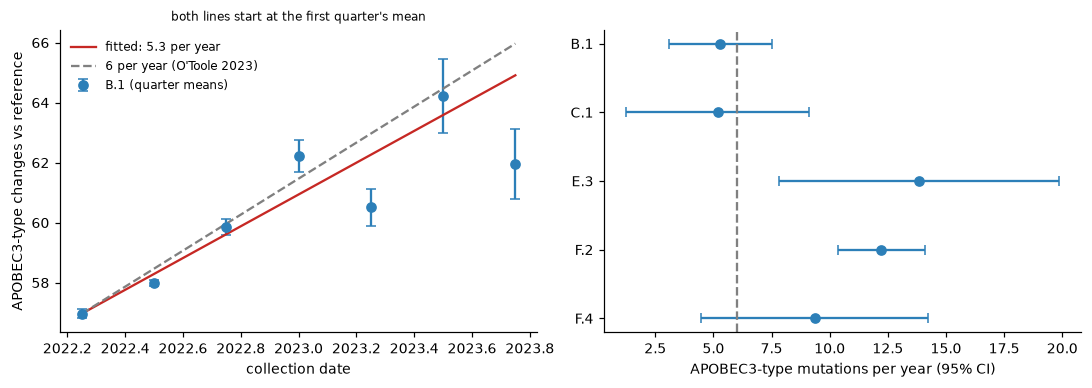

In [5]:
# B.1: the clock, binned by quarter
b = h[(h.Lineage.str.startswith("B.1")) & (h.dec_date < 2025)].copy()
b["q"] = (b.dec_date * 4).astype(int) / 4
g = b.groupby("q").n_apobec.agg(["mean", "sem", "count"]); g = g[g["count"] >= 20]
row = sl[(sl.lineage_grp == "B.1") & (sl.feature == "n_apobec")].iloc[0]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axs[0]
ax.errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], fmt="o", color="#2C7FB8", capsize=3, label="B.1 (quarter means)")
x = np.array([g.index.min(), g.index.max()]); y0 = g["mean"].iloc[0]
ax.plot(x, y0 + row.slope * (x - x[0]), color="#C62824", label=f"fitted: {row.slope:.1f} per year")
ax.plot(x, y0 + 6 * (x - x[0]), color="grey", ls="--", label="6 per year (O'Toole 2023)")
ax.set_title("both lines start at the first quarter's mean", fontsize=8)
ax.set_xlabel("collection date"); ax.set_ylabel("APOBEC3-type changes vs reference"); ax.legend(frameon=False, fontsize=8)
ax = axs[1]
s = sl[sl.feature == "n_apobec"].set_index("lineage_grp").reindex(["B.1", "C.1", "E.3", "F.2", "F.4"])
ax.errorbar(s.slope, range(len(s)), xerr=[s.slope - s.ci_lo, s.ci_hi - s.slope], fmt="o", color="#2C7FB8", capsize=3)
ax.axvline(6, color="grey", ls="--"); ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index)
ax.set_xlabel("APOBEC3-type mutations per year (95% CI)"); ax.invert_yaxis()
plt.tight_layout(); fig.savefig("results/figures/mpox_apobec3_clock.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.** In **B.1 the clock is 5.3 APOBEC3-type changes per year (95% interval 3.1 to 7.5)**, in line with the published ~6 per year, and the interval is clear of zero. This is a reproduction of a known result by an independent pipeline, which is what makes the rest trustworthy. C.1 gives the same rate (5.2).

E.3, F.2 and F.4 give faster rates (9 to 14 per year). Treat these with care: their errors are clustered by **year** with only 3-4 clusters (the lineages are too shallow to cluster by sub-lineage), so the intervals are less reliable, and a lineage that is a mixture of sub-lineages that diverged at different times inflates a pooled slope.

## 3. Does composition move as the clock predicts?

Each APOBEC3 change removes one G or C. If a lineage gains *k* net G/C losses per year, its GC content should fall by *k* divided by the genome length (about 197,000).

In [6]:
gc = sl[sl.feature == "gc_content"].set_index("lineage_grp")
loss = sl[sl.feature == "gc_loss"].set_index("lineage_grp")
tc = sl[sl.feature == "oe_TC"].set_index("lineage_grp")
order = ["B.1", "C.1", "E.3", "F.2", "F.4"]
out = pd.DataFrame({
    "predicted GC change per year": (-loss.slope / GLEN).reindex(order),
    "observed GC change per year": gc.slope.reindex(order),
    "observed 95% CI": [f"{gc.ci_lo[k]:.6f} to {gc.ci_hi[k]:.6f}" for k in order],
    "p (GC)": gc.p.reindex(order).round(3),
    "TpC O/E change per year": tc.slope.reindex(order).round(5),
    "p (TpC)": tc.p.reindex(order).round(3)})
out.round(6)

,predicted GC change per year,observed GC change per year,observed 95% CI,p (GC),TpC O/E change per year,p (TpC)
lineage_grp,,,,,,
B.1,-0.000026,-0.000050,-0.000239 to 0.000139,0.593,-0.00056,0.135
C.1,-0.000029,-0.000133,-0.000230 to -0.000036,0.022,-0.00076,0.001
E.3,-0.000074,-0.000079,-0.000129 to -0.000029,0.015,-0.00023,0.289
F.2,-0.000068,0.000013,-0.000066 to 0.000092,0.633,-0.00001,0.923
F.4,-0.000048,0.000164,-0.000623 to 0.000951,0.464,0.00116,0.249


**Reading it.** The **predicted** GC fall is tiny (about 0.00003 to 0.00007 per year) and the **observed** changes are mostly the same sign in B.1, C.1 and E.3 (F.2 and F.4 are positive but not significant). The genome-to-genome noise in GC (SD about 0.0002) is larger than the yearly effect, so **composition is a poor read-out**: GC is significant in only C.1 and E.3, and TpC in only C.1. Counting the mutations themselves (section 2) is far more sensitive than measuring the composition they change.

This matters for the project's design: for mpox, the question "does composition fall in sustained lineages" is answered more cleanly by the mutation spectrum than by GC content.

## 4. A sporadic-versus-sustained marker: the APOBEC3 share of recent mutations

The literature idea: a genome in a **sustained human chain** carries mostly APOBEC3-type recent mutations; a **zoonotic (sporadic) introduction** carries mutations of ordinary replication errors. For each genome, "recent" means the substitutions it has relative to its nearest neighbour in the Nextclade tree (so lineage-defining mutations are excluded).

In [7]:
x = h[h.priv_subs >= 5].copy()           # need at least 5 recent mutations for a share to mean anything
x["share"] = x.priv_apobec / x.priv_subs
fam = x.groupby("family").agg(genomes=("share", "size"), median_share=("share", "median"),
                              low_share_under_30pct=("share", lambda s: int((s < 0.3).sum())))
fam["% low share"] = (100 * fam.low_share_under_30pct / fam.genomes).round(0)
fam.round(2)

,genomes,median_share,low_share_under_30pct,% low share
family,,,,
A,56,0.83,17,30.0
B,630,0.80,67,11.0
C,49,0.80,6,12.0
E,222,0.89,3,1.0
F,318,0.62,46,14.0
G,5,1.00,0,0.0
H,11,0.74,0,0.0
J,5,0.83,1,20.0


In [8]:
a = h[h.family == "A"].groupby("Lineage").agg(genomes=("year", "size"), first=("year", "min"), last=("year", "max"),
                                           recent_mutations=("priv_subs", "sum"), apobec3_type=("priv_apobec", "sum"))
a["APOBEC3 share"] = (a.apobec3_type / a.recent_mutations).round(2)
a[a.recent_mutations > 0]

,genomes,first,last,recent_mutations,apobec3_type,APOBEC3 share
Lineage,,,,,,
A,43,2017,2026,121,48,0.40
A.1,17,2018,2025,1,1,1.00
A.2,12,2019,2022,72,41,0.57
A.2.1,35,2022,2022,76,50,0.66
A.2.2,16,2022,2025,114,32,0.28
A.2.3,49,2021,2024,328,175,0.53
A.2.4,11,2022,2022,67,34,0.51
A.2.5,15,2022,2022,125,39,0.31
A.3,8,2017,2023,32,1,0.03


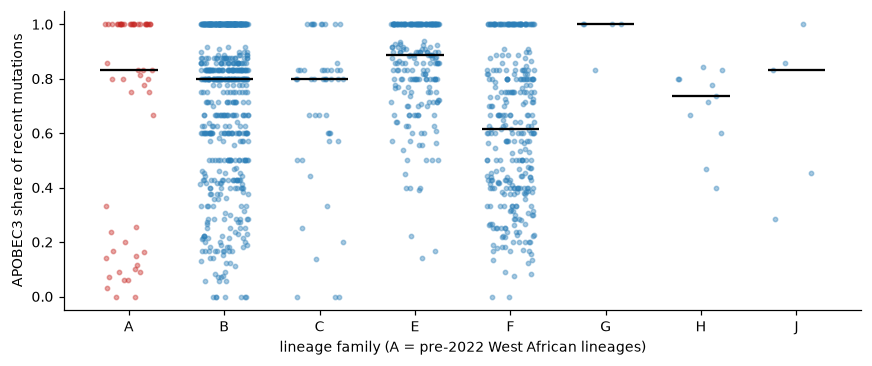

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
fams = [f for f in sorted(x.family.unique()) if (x.family == f).sum() >= 5]
for i, fm in enumerate(fams):
    v = x[x.family == fm].share
    ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-.25, .25, len(v)), v, s=8, alpha=.4,
               color="#C62824" if fm == "A" else "#2C7FB8")
    ax.hlines(v.median(), i - .3, i + .3, color="black")
ax.set_xticks(range(len(fams))); ax.set_xticklabels(fams)
ax.set_xlabel("lineage family (A = pre-2022 West African lineages)"); ax.set_ylabel("APOBEC3 share of recent mutations")
plt.tight_layout(); fig.savefig("results/figures/mpox_apobec3_share.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.**

- Lineage family **A** (the older West African lineages) has the widest spread: 30% of its genomes carry under 30% APOBEC3-type recent mutations, against 11% in B and 1% in E. Within A, **A.3 (8 genomes, 2017-2023) has only 3% APOBEC3-type** among its recent mutations, and A.2.2 and A.2.5 are around 30%, against family medians of 0.8 to 0.9 in B and E (the 2022 outbreak families). These are **candidates for sporadic (zoonotic) introductions**, consistent with the literature's finding that a few Nigerian sequences lack APOBEC3 enrichment.
- It is a **candidate list, not a classification**. A genome in a sparsely sampled part of the Nextclade tree has few close neighbours, so its "recent" mutations include older ones, which would lower its APOBEC3 share without any zoonotic origin. The numbers are also small (56 genomes in family A with at least 5 recent mutations).

## 5. What this means

| Question | Answer |
|---|---|
| Does mpox have a sporadic-versus-sustained contrast in our data? | **Weakly.** The A-family candidates (A.3, A.2.2, A.2.5) have a low APOBEC3 share, but this is 56 genomes and one caveat on tree sampling. |
| Does the pipeline find the known APOBEC3 clock? | **Yes.** B.1 gives 5.3 per year (3.1 to 7.5), matching the published ~6. |
| Does the composition follow it? | **Signs agree, but it is too noisy to test.** The mutation count is the better measure. |
| Can the RSV design run? | **Only in a weaker form:** no lineage spans 5 years; 5 lineages span 3-4. |

### A methodological warning

If we **classify** lineages as sustained by their APOBEC3 share and then **test** whether they have lower GC, the result is **circular**: APOBEC3 changes C to T, which lowers GC by definition. A real test needs a classification that does not use the mutation spectrum (for example, duration and size from the tree), then asks whether composition differs.

### Next steps

1. **Add clade I.** All complete genomes here are clade IIb. The literature's sharpest contrast is within clade I (Ia versus Ib; zoonotic spillovers versus a human-adapted outbreak). **Please export complete (high-coverage) clade I genomes from EpiPox**, with host, date and location.
2. **Define sporadic and sustained from the tree** (size and duration of each cluster), independent of the mutation spectrum, then compare composition and APOBEC3 share. This avoids the circularity above.
3. **Longer window for B.1 and A.2.** Dates are sparse before 2022; more sequences from Nigeria 2017-2021, if available, would give A.2 the five-year span the RSV design needs.